In [1]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="gpt-oss:120b-cloud")
print('Model is ready')


c:\Users\ak60492\AppData\Local\Programs\Python\Python312\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model is ready


In [2]:
# STEP 1: Define your state
from typing import TypedDict
from langchain_core.messages import AnyMessage
from langgraph.graph.message import Annotated, add_messages

class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], add_messages]

print('State is defined')

State is defined


In [4]:
# STEP 2: Define your nodes

def assistant_node(state: AgentState) -> dict:
    """One graph noce: call the LLM using current messages"""
    response = model.invoke(state['messages'])
    return {"messages": [response]}
print('Nodes are defined')

Nodes are defined


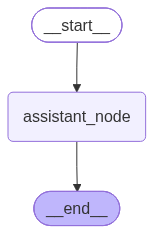

In [5]:
from langgraph.graph import StateGraph, START, END

graph_builder = StateGraph(AgentState)

# Node registration
graph_builder.add_node("assistant_node", assistant_node)

# Add edges to nodes
graph_builder.add_edge(START, "assistant_node")
graph_builder.add_edge("assistant_node", END)

graph = graph_builder.compile()
graph

In [6]:
response = graph.invoke({"messages": [{"role": "user", "content": "Which is the capital city of India?"}]})
response

{'messages': [HumanMessage(content='Which is the capital city of India?', additional_kwargs={}, response_metadata={}, id='cbc001fc-4c38-494d-8d4e-ce46ca6c90b0'),
  AIMessage(content='The capital city of India is **New\u202fDelhi**.', additional_kwargs={}, response_metadata={'model': 'gpt-oss:120b', 'created_at': '2026-10-23T04:46:15.000689701Z', 'done': True, 'done_reason': 'stop', 'total_duration': 287581410, 'load_duration': None, 'prompt_eval_count': 75, 'prompt_eval_duration': None, 'eval_count': 46, 'eval_duration': None, 'logprobs': None, 'model_name': 'gpt-oss:120b', 'model_provider': 'ollama'}, id='lc_run--01a16714-b406-7572-a220-b1ef8ae0243d-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 75, 'output_tokens': 46, 'total_tokens': 121})]}

In [7]:
response = graph.invoke({"messages": [{"role": "user", "content": "How is the weather in Pune today?"}]})
response

{'messages': [HumanMessage(content='How is the weather in Pune today?', additional_kwargs={}, response_metadata={}, id='95c0a0b2-fb77-43fb-9d3c-0804635ff5aa'),
  AIMessage(content='I’m not able to pull live weather data, so I can’t tell you the exact conditions in Pune right\u202fthis\u202fmoment. For the most up‑to‑date forecast, try one of these reliable sources:\n\n| Platform | How to use it |\n|----------|----------------|\n| **Weather.com** (The Weather Channel) | Search “Pune, India” for a detailed hourly and 10‑day forecast. |\n| **AccuWeather** | Same—type the city name and you’ll get temperature, humidity, chance of rain, UV index, etc. |\n| **Google** | Simply type “Pune weather” into the search bar and Google shows a quick summary (temp, feels‑like, chance of precipitation). |\n| **India Meteorological Department (IMD)** | The official government source; look under the “Regional forecasts” section for Maharashtra. |\n| **Smartphone weather apps** (Apple Weather, Android Weat